# Projeto 2: demonstração

Relações clínicas aprendidas com N-gramas + Machine Learning clássico, comparadas com as regras do Projeto 1.

O notebook só **carrega os resultados já calculados** pelo pipeline (`pipelines/workflows/run_all.sh`), então roda em segundos. Não é preciso baixar o MultiCaRe nem rodar o NER.

In [1]:
# No Colab: clona o repositório. Localmente: usa a pasta do projeto.
import os, sys
from pathlib import Path

REPO_URL = "https://github.com/lucas-lembo/NLP-Projeto2.git"

if "google.colab" in sys.modules:
    !git clone -q {REPO_URL} repo
    !pip -q install scikit-learn==1.6.1
    ROOT = Path("repo").resolve()
else:
    ROOT = Path.cwd().resolve().parents[1]  # pipelines/notebooks -> raiz do repositório

sys.path.insert(0, str(ROOT / "src"))
PROCESSED = ROOT / "data" / "processed"
IMAGES = ROOT / "assets" / "images"
print(ROOT)

/home/lucas_lembo/Disciplinas/MC896/projeto-2/project2


In [2]:
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 120)

## 1. Gatilhos aprendidos por N-grama + PMI

Para cada tipo de par, os N-gramas que mais aparecem **entre** as duas entidades, em comparação com os pares em geral: `PMI(g, T) = log2 P(g|T) / P(g)`. Calculado em 4.000 casos do MultiCaRe.

In [3]:
patterns = pd.read_csv(PROCESSED / "learned_patterns.csv")
patterns.groupby("pair_type").head(8).groupby("pair_type")["ngram"].apply(", ".join).to_frame("top 8 N-gramas")

,top 8 N-gramas
pair_type,
diagnosis-anatomical_site,"involving the, involving, biopsy, consistent with, consistent, metastatic, no evidence, no evidence of"
diagnosis-treatment,"started on, was started on, with intravenous, was treated with, treated with, was treated, was started, antibiotics"
exam-anatomical_site,"ct of the, scan of the, the abdomen and, ct of, scan of, abdomen and, of the abdomen, ct scan of"
exam-diagnosis,"confirmed, hemoglobin, diagnosis of, out, diagnosis, was performed, demonstrated, mild"
exam-symptom,"ecg, sinus, significant, revealed, showed, demonstrated, mild, patient"
symptom-diagnosis,"chronic kidney, obstructive, failure, fever, nausea, hypertension, heart, symptoms"
treatment-anatomical_site,"extracted from, extracted, liver function, hormone, were positive for, staining, electrolytes, levels of"


O PMI redescobre os gatilhos escritos à mão no Projeto 1 (`triggers.csv`)? `rank` vazio significa que o gatilho não aparece entre os padrões (frequência < 20 ou PMI ≤ 0).

In [4]:
pd.read_csv(PROCESSED / "p1_triggers_vs_pmi.csv").sort_values("rank")

,trigger,use,pair_type,rank,pmi,count
19,started on,administration,diagnosis-treatment,1.0,3.253,34.0
30,confirmed,exam_result,exam-diagnosis,1.0,2.384,68.0
25,revealed,exam_result,exam-symptom,4.0,1.539,229.0
21,showed,exam_result,exam-symptom,5.0,1.526,261.0
18,treated with,administration,diagnosis-treatment,5.0,3.059,80.0
23,demonstrated,exam_result,exam-symptom,6.0,1.470,33.0
22,demonstrated,exam_result,exam-diagnosis,7.0,1.566,32.0
24,revealed,exam_result,exam-diagnosis,10.0,1.484,200.0
31,confirmed,exam_result,exam-symptom,11.0,1.063,30.0
20,showed,exam_result,exam-diagnosis,12.0,1.047,170.0


## 2. Regras do Projeto 1 × classificadores do Projeto 2

Avaliação nos 210 pares anotados dos 56 casos do Projeto 1 (fora do treino).

,system,precision,recall,f1,detect_precision,detect_recall,detect_f1,predicted_relations
0,p1_rules,0.359,0.684,0.471,0.372,0.711,0.489,145
1,cooccurrence,0.305,0.842,0.448,0.362,1.000,0.531,210
2,weak_rules,0.540,0.355,0.429,0.600,0.395,0.476,50
3,logreg_ngram1,0.425,0.632,0.508,0.496,0.737,0.593,113
4,logreg_ngram2,0.420,0.658,0.513,0.479,0.750,0.585,119
5,logreg_ngram3,0.405,0.645,0.497,0.471,0.750,0.579,121
6,nb_ngram1,0.423,0.434,0.429,0.538,0.553,0.545,78
7,nb_ngram2,0.519,0.355,0.422,0.654,0.447,0.531,52
8,nb_ngram3,0.594,0.250,0.352,0.750,0.316,0.444,32
9,logreg_ngram2_noP1,0.407,0.632,0.495,0.492,0.763,0.598,118


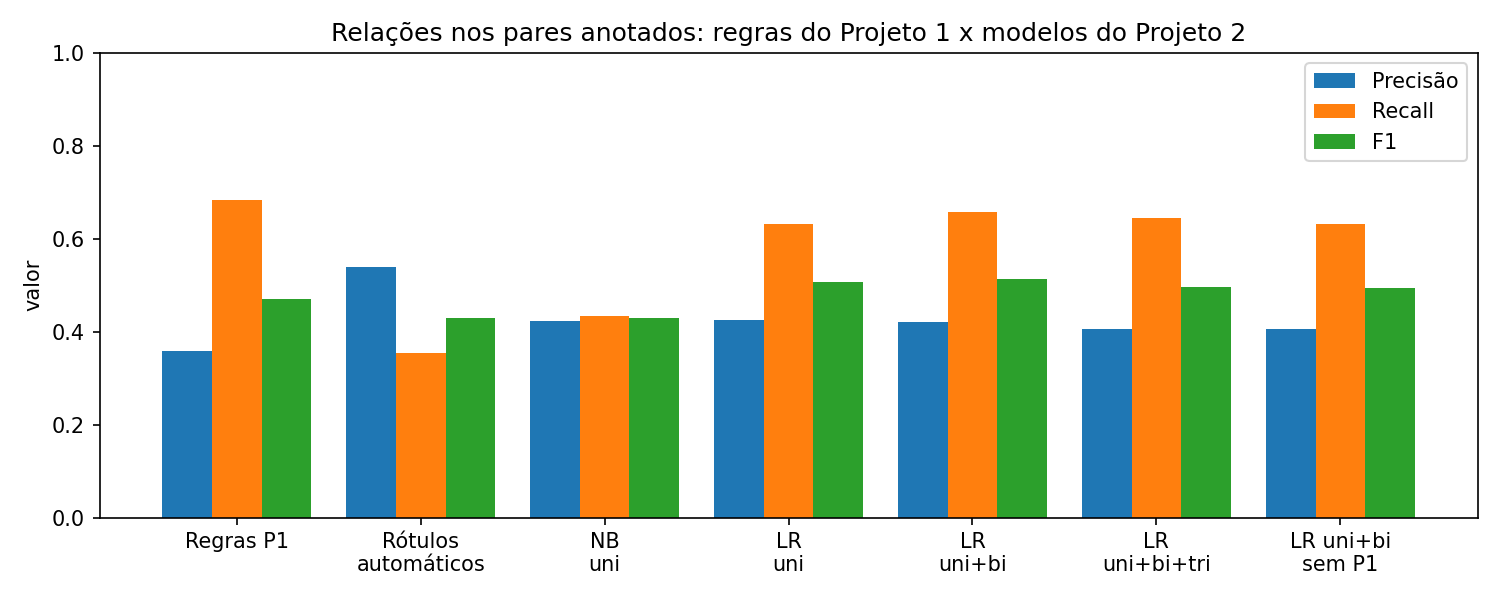

In [5]:
metrics = pd.read_csv(PROCESSED / "metrics.csv")
display(metrics)
display(Image(str(IMAGES / "metricas.png")))

In [6]:
pd.read_csv(PROCESSED / "metrics_by_pair_type.csv").pivot(index="pair_type", columns="system", values="f1")

system,logreg_ngram2,p1_rules,weak_rules
pair_type,,,
diagnosis-anatomical_site,0.552,0.500,0.444
diagnosis-treatment,0.647,0.696,0.500
exam-anatomical_site,0.353,0.636,0.133
exam-diagnosis,0.486,0.300,0.417
exam-symptom,0.605,0.583,0.690
symptom-diagnosis,0.381,0.333,0.167
treatment-anatomical_site,0.286,0.235,0.250


N-gramas com maior peso na Regressão Logística, por relação:

In [7]:
top = pd.read_csv(PROCESSED / "top_features.csv")
top.groupby("label").head(6).groupby("label")["feature"].apply(", ".join).to_frame("atributos mais fortes")

,atributos mais fortes
label,
CONFIRMS,"between__suggestive of, between__suggestive, between__consistent with, between__consistent, between__positive for, b..."
EXCLUDES,"between__negative for, between__no, between__negative, between__excluded, between__without, between__no evidence"
LOCATED_IN,"meta__pair_type_diagnosis-anatomical_site, between__disease, between__without, between__bilateral, between__biopsy, ..."
NONE,"between__,, between__;, between__but, meta__distance_11+, between__, but, between__mg"
PERFORMED_ON,"meta__pair_type_exam-anatomical_site, meta__distance_0-2, between__soft, between__tender, between__that, between__th..."
REVEALS,"between__revealed, between__showed, meta__pair_type_exam-symptom, meta__pair_type_exam-diagnosis, between__performed..."
SUPPORTS,"meta__pair_type_symptom-diagnosis, between__chronic, between__severe, between__and, between__associated, between__sy..."
TARGETS,"meta__pair_type_treatment-anatomical_site, between__positive, between__using, between__level, between__levels, betwe..."
TREATED_BY,"meta__pair_type_diagnosis-treatment, between__treated, between__treatment, between__treated with, between__patient, ..."


## 3. Teste o classificador numa frase

Marque as duas entidades com `[E1 ...]` e `[E2 ...]` e informe os tipos. Os pares possíveis são: diagnosis-treatment, symptom-diagnosis, diagnosis-anatomical_site, treatment-anatomical_site, exam-anatomical_site, exam-diagnosis, exam-symptom.

O 2º exemplo mostra uma limitação: "received" é um gatilho forte de tratamento, e o modelo não percebe que o heparin é para a trombose, não para a asma.

In [8]:
import re
import joblib
from kg_ml.features import predict_allowed

model = joblib.load(PROCESSED / "relation_model.joblib")
WORD_RE = re.compile(r"[A-Za-z][A-Za-z\-]*|\d[\d,\.]*")

def words(text):
    return [w.lower() for w in WORD_RE.findall(text)]

def classify(marked, e1_type, e2_type):
    plain = re.sub(r"\[E[12] ([^\]]+)\]", r"\1", marked)
    spans = {}
    offset = 0
    for m in re.finditer(r"\[(E[12]) ([^\]]+)\]", marked):
        start = m.start() - offset
        spans[m.group(1)] = (start, start + len(m.group(2)))
        offset += len(m.group(0)) - len(m.group(2))
    (s1, e1), (s2, e2) = spans["E1"], spans["E2"]
    first_end, second_start = min(e1, e2), max(s1, s2)
    between = plain[first_end:second_start]
    row = pd.DataFrame([{
        "e1_type": e1_type, "e2_type": e2_type, "pair_type": f"{e1_type}-{e2_type}",
        "between": between, "n_between": len(words(between)), "e1_first": s1 < s2,
        "left": " ".join(words(plain[:min(s1, s2)])[-3:]),
        "right": " ".join(words(plain[max(e1, e2):])[:3]),
    }])
    labels, scores = predict_allowed(model, row)
    return labels[0], round(scores[0], 3)

examples = [
    ("The patient was diagnosed with [E1 herpes zoster] and treated with [E2 acyclovir].", "diagnosis", "treatment", "TREATED_BY"),
    ("[E1 Asthma] was controlled; months later she received [E2 heparin] for a thrombosis.", "diagnosis", "treatment", "NONE"),
    ("The [E1 colonoscopy] showed extensive [E2 colitis].", "exam", "diagnosis", "REVEALS"),
    ("[E1 Biopsy] showed no evidence of [E2 lymphoma].", "exam", "diagnosis", "EXCLUDES"),
    ("[E1 Fever] and cough were attributed to [E2 pneumonia].", "symptom", "diagnosis", "SUPPORTS"),
]
pd.DataFrame([(s, esperado, *classify(s, a, b)) for s, a, b, esperado in examples],
             columns=["frase", "esperado", "relação prevista", "P(relação)"])

,frase,esperado,relação prevista,P(relação)
0,The patient was diagnosed with [E1 herpes zoster] and treated with [E2 acyclovir].,TREATED_BY,TREATED_BY,0.998
1,[E1 Asthma] was controlled; months later she received [E2 heparin] for a thrombosis.,NONE,TREATED_BY,0.927
2,The [E1 colonoscopy] showed extensive [E2 colitis].,REVEALS,REVEALS,0.999
3,[E1 Biopsy] showed no evidence of [E2 lymphoma].,EXCLUDES,EXCLUDES,1.000
4,[E1 Fever] and cough were attributed to [E2 pneumonia].,SUPPORTS,SUPPORTS,0.845


## 4. Grafo do Projeto 1 × grafo do Projeto 2

Os nós são os mesmos (mesmo NER). Mudam as arestas entre entidades: no P1 elas vêm das regras; no P2, do classificador, cada uma com sua probabilidade.

,relation,p1,p2,both,only_p1,only_p2
0,CONFIRMS,3,3,1,2,2
1,EXCLUDES,1,5,0,1,5
2,LOCATED_IN,84,51,51,33,0
3,PERFORMED_ON,172,42,42,130,0
4,REVEALS,19,77,18,1,59
5,SUPPORTS,47,22,22,25,0
6,TARGETS,143,49,49,94,0
7,TREATED_BY,179,30,11,168,19
8,TOTAL,648,279,194,454,85


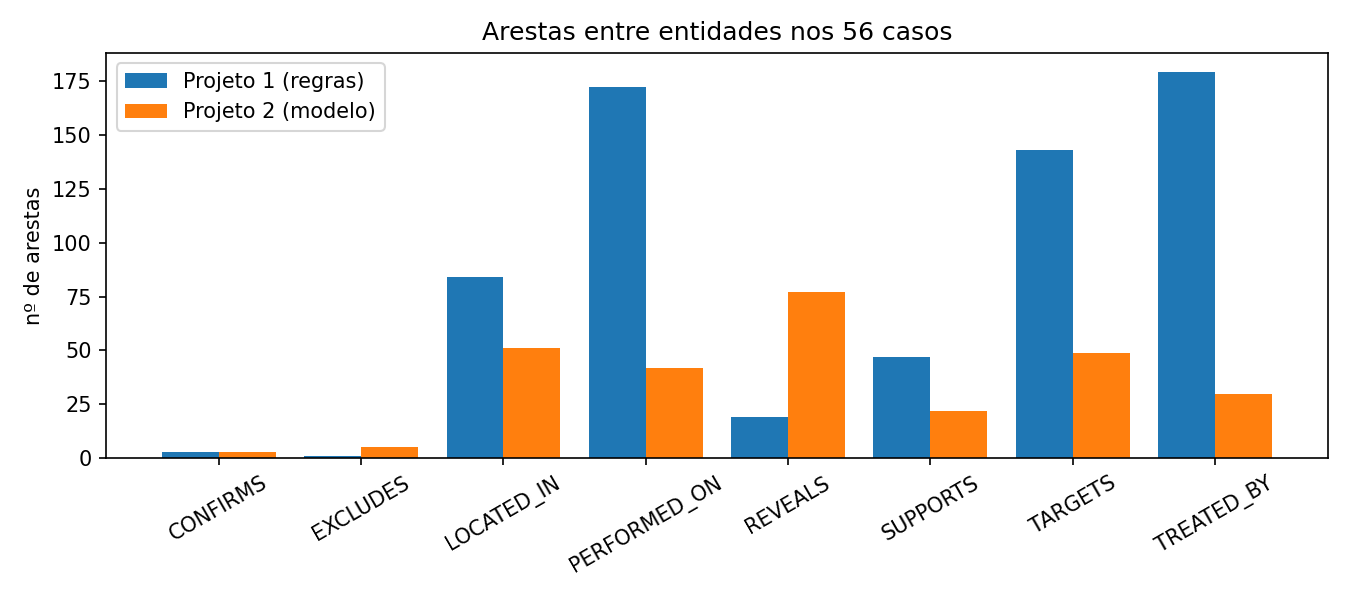

In [9]:
display(pd.read_csv(PROCESSED / "graph_comparison.csv"))
display(Image(str(IMAGES / "comparacao-grafos.png")))

In [10]:
# Um caso lado a lado
CASE = "PMC7102447_01"
nodes = pd.read_csv(PROCESSED / "nodes.csv")
labels = dict(zip(nodes["node_id"], nodes["label"]))
entity_rel = ["TREATED_BY", "SUPPORTS", "LOCATED_IN", "TARGETS", "PERFORMED_ON", "CONFIRMS", "EXCLUDES", "REVEALS"]

def case_edges(path):
    e = pd.read_csv(path)
    e = e[(e["case_id"] == CASE) & e["relation"].isin(entity_rel)].copy()
    e["source"] = e["source_id"].map(labels)
    e["target"] = e["target_id"].map(labels)
    return e[["source", "relation", "target", "attributes"]]

p1_edges = ROOT.parents[1] / "NLP-Projeto1" / "data" / "processed" / "edges.csv"
if p1_edges.exists():
    print("Projeto 1:"); display(case_edges(p1_edges))
print("Projeto 2:"); display(case_edges(PROCESSED / "edges.csv"))

Projeto 1:


,source,relation,target,attributes
69,Hypertension,LOCATED_IN,Mitral Valve,NaN
70,Asthma,LOCATED_IN,Mitral Valve,NaN
73,Electrocardiography,REVEALS,Bundle-Branch Block,NaN
78,Asthma,TREATED_BY,Critical Care,NaN
80,Asthma,TREATED_BY,Heparin,NaN
84,Edema,SUPPORTS,Acute Coronary Syndrome,NaN
85,Cardiomegaly,SUPPORTS,Acute Coronary Syndrome,NaN
87,Tomography,REVEALS,moderate patchy ground-glass and nodular airspace opacities,NaN
89,Angiography,REVEALS,moderate patchy ground-glass and nodular airspace opacities,NaN
91,Thrombosis,LOCATED_IN,Mitral Valve,NaN


Projeto 2:


,source,relation,target,attributes
63,Tomography,REVEALS,moderate patchy ground-glass and nodular airspace opacities,NaN
65,Angiography,REVEALS,moderate patchy ground-glass and nodular airspace opacities,NaN
1302,Hypertension,LOCATED_IN,Mitral Valve,prob=0.632
1303,Asthma,LOCATED_IN,Mitral Valve,prob=0.746
1304,Electrocardiography,REVEALS,Bundle-Branch Block,prob=0.993
1305,Acute Coronary Syndrome,TREATED_BY,Critical Care,prob=0.891
1306,Acute Coronary Syndrome,TREATED_BY,Heparin,prob=0.784
1307,Tomography,REVEALS,Acute Coronary Syndrome,prob=0.587
1308,Tomography,REVEALS,Edema,prob=0.978
1309,Tomography,REVEALS,Cardiomegaly,prob=0.970


## 5. Grafo de associação por PMI

Conceitos que aparecem juntos nos mesmos casos com frequência maior que o acaso. É uma camada de "conhecimento do corpus", diferente das relações afirmadas em cada frase.

,source_type,source,target_type,target,cases_together,pmi
30,exam,Mammography,anatomical_site,Breast,17,5.476
34,treatment,Chromatin,anatomical_site,Cytoplasm,25,5.439
57,diagnosis,Hypothyroidism,treatment,Thyroxine,17,5.209
90,diagnosis,Osteoarthritis,anatomical_site,Knee,15,4.815
97,diagnosis,Breast Neoplasms,anatomical_site,Breast,22,4.774
142,exam,Visual Acuity,anatomical_site,Anterior Chamber,17,4.380
149,exam,Colonoscopy,diagnosis,Colitis,18,4.353
153,exam,Visual Acuity,diagnosis,Cataract,17,4.332
154,exam,Urinalysis,symptom,Proteinuria,24,4.329
155,exam,Colonoscopy,anatomical_site,Colon,40,4.328


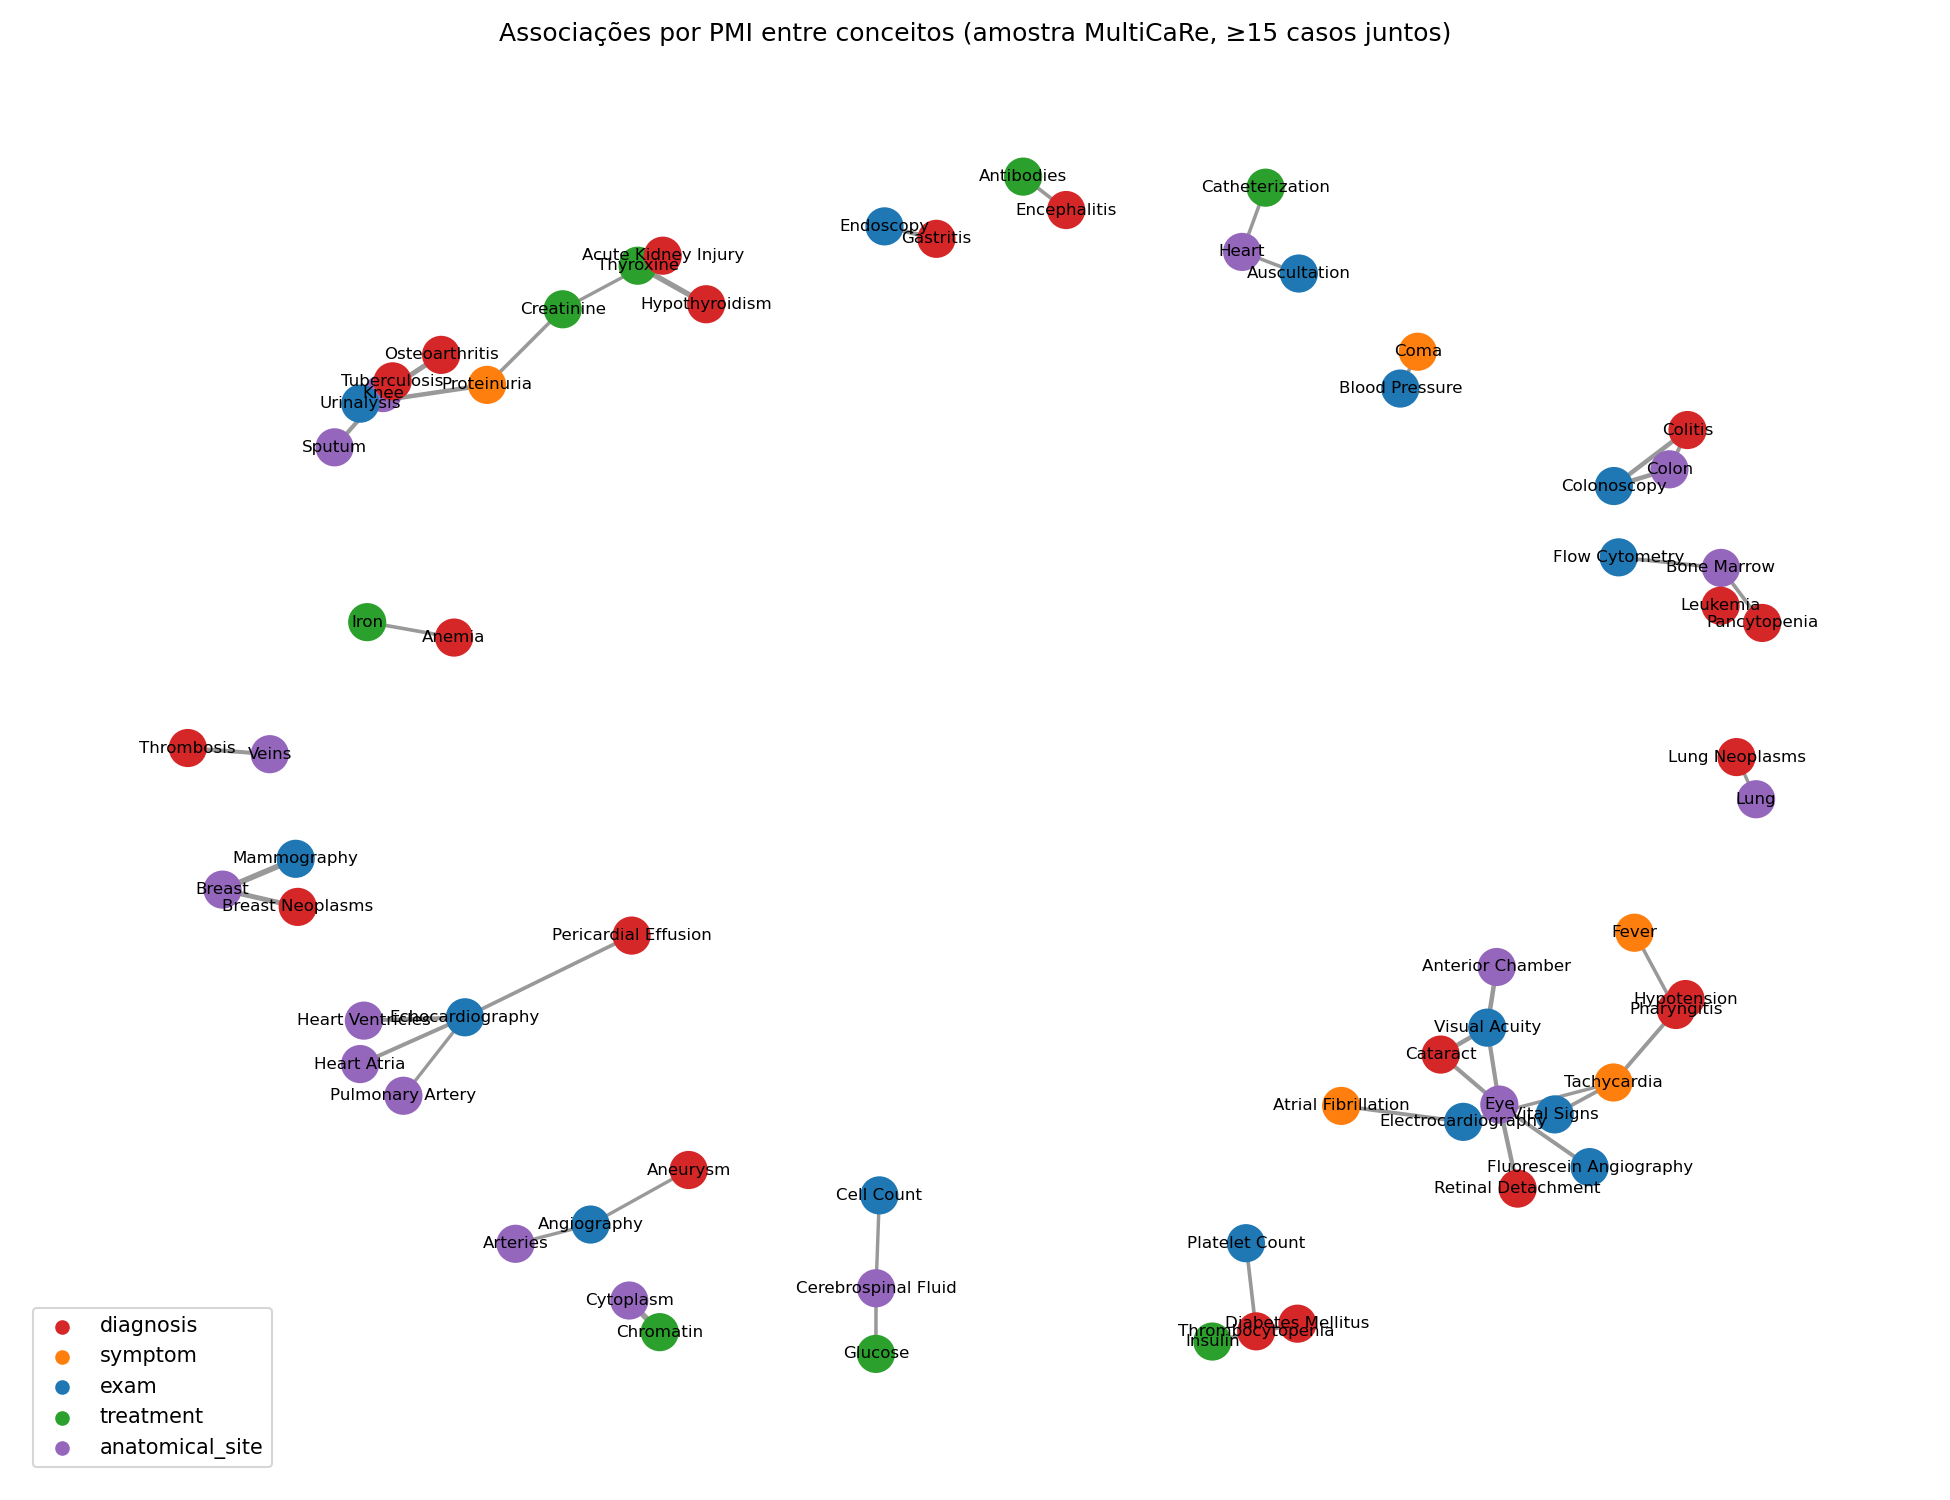

In [11]:
display(pd.read_csv(PROCESSED / "concept_pmi.csv").query("cases_together >= 15").head(15))
display(Image(str(IMAGES / "grafo-associacao-pmi.png")))